# Income vs. Education: Exploratory and Statistical Analysis

## 1. Introduction

Education is often associated with differences in employment opportunities and earnings. This project investigates the relationship between educational attainment and income using the Adult Census Income dataset.

The main objective is to examine whether income distribution differs across education levels and whether individuals with higher educational attainment are more likely to earn more than $50,000 annually. The analysis combines exploratory data analysis (EDA), descriptive statistics, correlation analysis, and hypothesis testing to identify and evaluate these relationships.

The project focuses on three main questions:

- How does the proportion of individuals earning more than $50,000 vary across education groups?
- Is educational attainment statistically associated with income category?
- How strong is the observed relationship between education level and income?

The findings are interpreted in terms of statistical significance, effect size, and the limitations of observational data.

## 2. Dataset Overview

This project uses the **Adult Census Income dataset**, which contains demographic, educational, and employment-related information about individuals. The original dataset loaded in this notebook contains **32,561 rows and 15 columns**.

The target variable is `income`, which has two categories:

- `<=50K`: Annual income of $50,000  or less.

- `>50K`: Annual income greater than $50,000.

The analysis primarily focuses on three variables:

- `education`: The categorical educational attainment level, containing 16 original categories.
- `education.num`: A numerical representation of educational attainment.
- `income`: The binary income category used as the target variable.

For clearer comparisons, the original education categories are consolidated into five groups:

| Education group | Included categories |
|---|---|
| Pre-High School | Preschool, 1st–4th, 5th–6th, 7th–8th, 9th, 10th, 11th, 12th |
| High School | HS-grad |
| Some College / Associate | Some-college, Assoc-voc, Assoc-acdm |
| Bachelor's | Bachelors |
| Advanced Degree | Masters, Prof-school, Doctorate |

The `Advanced Degree` category combines master's, professional-school, and doctoral qualifications. It therefore represents a broader group rather than a single degree level.

Grouping the original categories makes the results easier to interpret while preserving a meaningful ordering of educational attainment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Null values are stored as '?'

In [2]:
df = pd.read_csv('adult.csv' , na_values='?')

In [3]:
df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [4]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [5]:
df.isna().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

In [6]:
df.shape

(32561, 15)

In [7]:
#drop null vals and duplicates
df1 = df.dropna().drop_duplicates().copy()

In [8]:
df1.shape

(30139, 15)

In [9]:
# make the income as binary
df1['bi_income'] = (df1['income'] == '>50K').astype(int)

In [10]:
df1

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,bi_income
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K,0
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K,0
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K,0
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K,0
6,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K,0
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K,1
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K,0


## 3. Data Preparation

Data preparation was performed to improve consistency and ensure that the statistical analyses use valid observations.

The following steps were applied:

1. Values represented by `?` were treated as missing values.
2. Rows containing missing values were removed.
3. Duplicate rows were dropped.
4. The original education categories were consolidated into five education groups.
5. A binary variable, `bi_income`, was created to represent the income category numerically.

The binary variable is defined as follows:

- `1`: Income greater than $50,000.
  
- `0`: Income of $50,000 or less.

After removing missing and duplicate records, the dataset contained **30,139 observations**, compared with 32,561 observations initially.

Removing incomplete observations simplifies the analysis, but it may introduce selection bias if missing values are systematically related to education or income. Consequently, the findings should be interpreted in the context of the retained sample.

In [11]:
df1['education.num'].nunique()

16

In [12]:
df2 = df1.sort_values(by = 'education.num').reset_index()

In [13]:
df2['education.num'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16])

In [14]:
df2['education'].unique()

array(['Preschool', '1st-4th', '5th-6th', '7th-8th', '9th', '10th',
       '11th', '12th', 'HS-grad', 'Some-college', 'Assoc-voc',
       'Assoc-acdm', 'Bachelors', 'Masters', 'Prof-school', 'Doctorate'],
      dtype=object)

In [15]:
df2['education'].nunique()

16

In [16]:
# Define education groups
def education_gp (edu):
    if edu in ['Preschool', '1st-4th', '5th-6th', '7th-8th', '9th', '10th', '11th', '12th']:
        return '1. Pre-High School'
    if edu in ['HS-grad']:
        return '2. High School'
    if edu in ['Some-college', 'Assoc-voc', 'Assoc-acdm']:
        return '3. Some College / Assoc'
    if edu in ['Bachelors']:
        return '4. Bachelors'
    if edu in ['Masters', 'Prof-school', 'Doctorate']:
        return '5. Advanced Degree (MSc/PhD/Prof)'
    return 'Other'
    

In [17]:
df2['education_group'] = df2['education'].apply(education_gp)

In [18]:
df2

,index,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,bi_income,education_group
0,1678,27,Private,211032,Preschool,1,Married-civ-spouse,Farming-fishing,Other-relative,White,Male,41310,0,24,Mexico,<=50K,0,1. Pre-High School
1,10374,30,Private,193598,Preschool,1,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,Mexico,<=50K,0,1. Pre-High School
2,24227,25,Private,266820,Preschool,1,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,35,Mexico,<=50K,0,1. Pre-High School
3,13209,59,Private,157305,Preschool,1,Never-married,Machine-op-inspct,Not-in-family,White,Male,0,0,40,Dominican-Republic,<=50K,0,1. Pre-High School
4,3260,32,Private,112137,Preschool,1,Married-civ-spouse,Machine-op-inspct,Wife,Asian-Pac-Islander,Female,4508,0,40,Cambodia,<=50K,0,1. Pre-High School
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30134,38,37,Self-emp-not-inc,137527,Doctorate,16,Never-married,Prof-specialty,Not-in-family,White,Female,0,2559,60,United-States,>50K,1,5. Advanced Degree (MSc/PhD/Prof)
30135,32535,34,Private,204461,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,>50K,1,5. Advanced Degree (MSc/PhD/Prof)
30136,10,45,Private,172274,Doctorate,16,Divorced,Prof-specialty,Unmarried,Black,Female,0,3004,35,United-States,>50K,1,5. Advanced Degree (MSc/PhD/Prof)
30137,35,63,Federal-gov,39181,Doctorate,16,Divorced,Exec-managerial,Not-in-family,White,Female,0,2559,60,United-States,>50K,1,5. Advanced Degree (MSc/PhD/Prof)


In [19]:
print(df2['education_group'].value_counts().sort_index())

education_group
1. Pre-High School                   3736
2. High School                       9834
3. Some College / Assoc              8984
4. Bachelors                         5042
5. Advanced Degree (MSc/PhD/Prof)    2543
Name: count, dtype: int64


In [20]:
#Compare income across groups
income_comparison = df2.groupby('education_group')['bi_income'].agg(
    Total_Count='count',
    High_Income_Count='sum',
    High_Income_Rate=lambda x: x.mean() * 100
).reset_index()

print(income_comparison.to_string(index=False))

                  education_group  Total_Count  High_Income_Count  High_Income_Rate
               1. Pre-High School         3736                225          6.022484
                   2. High School         9834               1616         16.432784
          3. Some College / Assoc         8984               1935         21.538290
                     4. Bachelors         5042               2126         42.165807
5. Advanced Degree (MSc/PhD/Prof)         2543               1604         63.075108


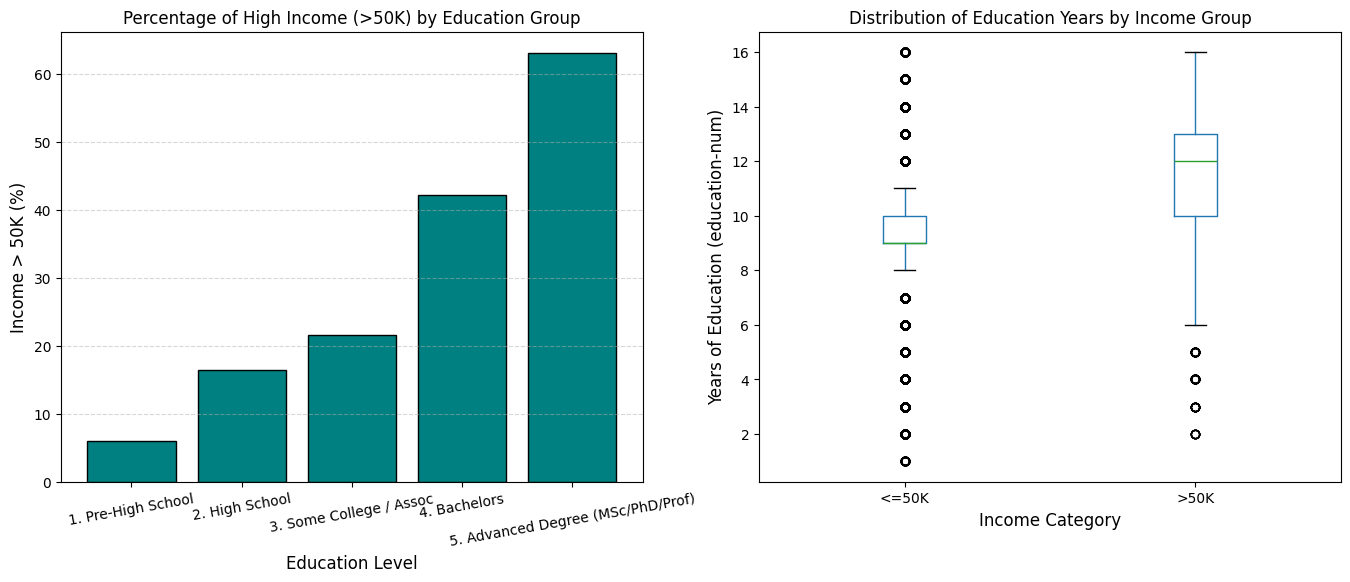

In [21]:
fig, axes = plt.subplots(1,2 , figsize=(16,6))

axes[0].bar(income_comparison['education_group'], income_comparison['High_Income_Rate'] ,color='teal' , edgecolor='black' )
axes[0].set_title('Percentage of High Income (>50K) by Education Group',fontsize=12)
axes[0].set_xlabel('Education Level' ,fontsize=12)
axes[0].set_ylabel('Income > 50K (%)' ,fontsize=12)
axes[0].tick_params(axis = 'x' , rotation=10)
axes[0].grid(axis='y' , alpha= 0.5 , linestyle= '--')

df2.boxplot(column = 'education.num' , by='income' , ax=axes[1] , grid=False)
axes[1].set_title('Distribution of Education Years by Income Group',fontsize=12)
axes[1].set_xlabel('Income Category' ,fontsize=12)
axes[1].set_ylabel('Years of Education (education-num)' ,fontsize=12)


plt.suptitle('')
plt.show()

## 4. Descriptive Results

The descriptive analysis examines the proportion of individuals earning more than $50,000 within each education group.

| Education group | Total observations | Income > $50K | High-income rate |
|---|---:|---:|---:|
| Pre-High School | 3,736 | 225 | 6.02% |
| High School | 9,834 | 1,616 | 16.43% |
| Some College / Associate | 8,984 | 1,935 | 21.54% |
| Bachelor's | 5,042 | 2,126 | 42.17% |
| Advanced Degree | 2,543 | 1,604 | 63.08% |

### Key Findings

The proportion of individuals earning more than $50,000 increases consistently across the five education groups.

The Pre-High School group has the lowest high-income rate, at **6.02%**, whereas the Advanced Degree group has the highest rate, at **63.08%**. This represents a difference of approximately **57.05 percentage points**.

The Bachelor's group also shows a substantial increase, with 42.17% of its members earning more than $50,000, compared with 21.54% in the Some College / Associate group.

These results suggest a clear positive descriptive relationship between educational attainment and income category.

The reported percentages are calculated within each education group. They should not be confused with the proportion of all high-income individuals belonging to a particular group, because the groups have different sample sizes.

The boxplot comparing `education.num` across income categories provides a complementary view of the distributions. Differences between the distributions are consistent with an association between education level and income, although descriptive plots alone cannot establish statistical significance or causality.

In [22]:
#Choose an appropriate correlation measure
from scipy.stats import spearmanr, pointbiserialr

In [23]:
r_pb , p_pb = pointbiserialr(df2['bi_income'] , df2['education.num'])
r_sp , p_sp = spearmanr(df2['education.num'] , df2['bi_income'])

print(f"Point-Biserial Correlation: r = {r_pb:.4f} (p-value = {p_pb:.4e})")
print(f"Spearman Rank Correlation : rho = {r_sp:.4f} (p-value = {p_sp:.4e})")

Point-Biserial Correlation: r = 0.3354 (p-value = 0.0000e+00)
Spearman Rank Correlation : rho = 0.3300 (p-value = 0.0000e+00)


## 5. Correlation Analysis

Correlation analysis was used to evaluate the direction and strength of the relationship between educational attainment and income.

The analysis considers two correlation measures:

- **Point-biserial correlation:** Measures the linear association between a numerical variable and a binary variable.
- **Spearman's rank correlation:** Measures the strength and direction of a monotonic relationship using ranked values.

The `education.num` variable represents ordered educational attainment, while `bi_income` indicates whether an individual's income exceeds $50,000.

### Point-Biserial Correlation

The point-biserial correlation coefficient is **0.3354**, with a p-value below 0.001.

The positive coefficient indicates that higher numerical education levels tend to be associated with the high-income category. The result is statistically significant at the 5% significance level.

### Spearman's Rank Correlation

The Spearman correlation coefficient is **0.33**, with a p-value below 0.001.

A positive Spearman coefficient indicates that higher educational attainment tends to correspond to a higher probability of belonging to the `>50K` income category. The p-value determines whether this monotonic association is statistically significant at the selected significance level.

Taken together, these measures provide complementary evidence about the relationship between educational attainment and income. However, correlation does not establish a causal relationship, and neither coefficient controls for other factors that may influence earnings.

### Statistical Hypotheses & Test Selection

To formally test whether education level و income are statistically independent or associated, we use the **Chi-Square Test of Independence ($\chi^2$)** on the contingency table of `education_group` and `income`.

* **Null Hypothesis ($H_0$):** Education level and income level are independent (there is no statistically significant relationship between education group and earning $>50\text{K}$).
* **Alternative Hypothesis ($H_1$):** Education level and income level are not independent (there is a statistically significant relationship between education group and earning $>50\text{K}$).
* **Significance Level ($\alpha$):** $\alpha = 0.05$

In [24]:
from scipy.stats import chi2_contingency

In [25]:
##Contingency table
contingency_table = pd.crosstab(df2['education_group'],df2['income'])

In [26]:
contingency_table

income,<=50K,>50K
education_group,,
1. Pre-High School,3511,225
2. High School,8218,1616
3. Some College / Assoc,7049,1935
4. Bachelors,2916,2126
5. Advanced Degree (MSc/PhD/Prof),939,1604


In [27]:
#Chi-Square Test
chi2_stat, p_val, dof, expected = chi2_contingency(contingency_table)

In [28]:
contingency_table.sum()

income
<=50K    22633
>50K      7506
dtype: int64

In [29]:
contingency_table.sum().sum()

np.int64(30139)

In [30]:
n = contingency_table.sum().sum()

In [31]:
min_dim = min(contingency_table.shape) - 1

In [32]:
cramers_v = np.sqrt(chi2_stat / (n*min_dim))

In [38]:
print(f"Chi-Square Statistic : {chi2_stat:.4f}")
print(f"Degrees of Freedom   : {dof}")
print(f"P-value              : {p_val:.4e}")
print(f"Cramér's V (Effect)  : {cramers_v:.4f}")

Chi-Square Statistic : 3928.4129
Degrees of Freedom   : 4
P-value              : 0.0000e+00
Cramér's V (Effect)  : 0.3610


In [39]:
alpha = 0.05
if p_val < alpha:
    print("\nConclusion: Reject H0 -> Strong statistically significant relationship between education and income.")
else:
    print("\nConclusion: Fail to reject H0 -> No significant relationship.")


Conclusion: Reject H0 -> Strong statistically significant relationship between education and income.


## 6. Chi-Square Test of Independence

The Chi-Square Test of Independence was conducted to determine whether education group and income category are statistically associated.

### Hypotheses

- **Null hypothesis (H₀):** Education group and income category are independent.
- **Alternative hypothesis (H₁):** Education group and income category are associated.
- **Significance level:** α = 0.05.

### Test Results

| Statistic | Result |
|---|---:|
| Chi-square statistic | 3928.4129 |
| Degrees of freedom | 4 |
| p-value | p < 0.001 |
| Cramér's V | 0.3610 |
| Sample size | 30,139 |

### Interpretation

The p-value is below the significance level of 0.05. Therefore, the null hypothesis of independence is rejected.

There is strong statistical evidence of an association between education group and income category in the analyzed sample.

Cramér's V is **0.3610**, indicating a substantial association in this context. Unlike the p-value, which evaluates statistical evidence against the null hypothesis, Cramér's V provides information about the magnitude of the association.

The result indicates that income category varies across education groups. However, the Chi-Square Test does not identify causality or establish that education alone explains differences in income.

The interpretation assumes that the observations are independent and that the expected cell frequencies are sufficiently large for the Chi-Square approximation to be appropriate.

In [40]:
#Support conclusion with visualization
prop_table = pd.crosstab(df2['education_group'],df2['income'] , normalize = 'index')*100
prop_table

income,<=50K,>50K
education_group,,
1. Pre-High School,93.977516,6.022484
2. High School,83.567216,16.432784
3. Some College / Assoc,78.461710,21.538290
4. Bachelors,57.834193,42.165807
5. Advanced Degree (MSc/PhD/Prof),36.924892,63.075108


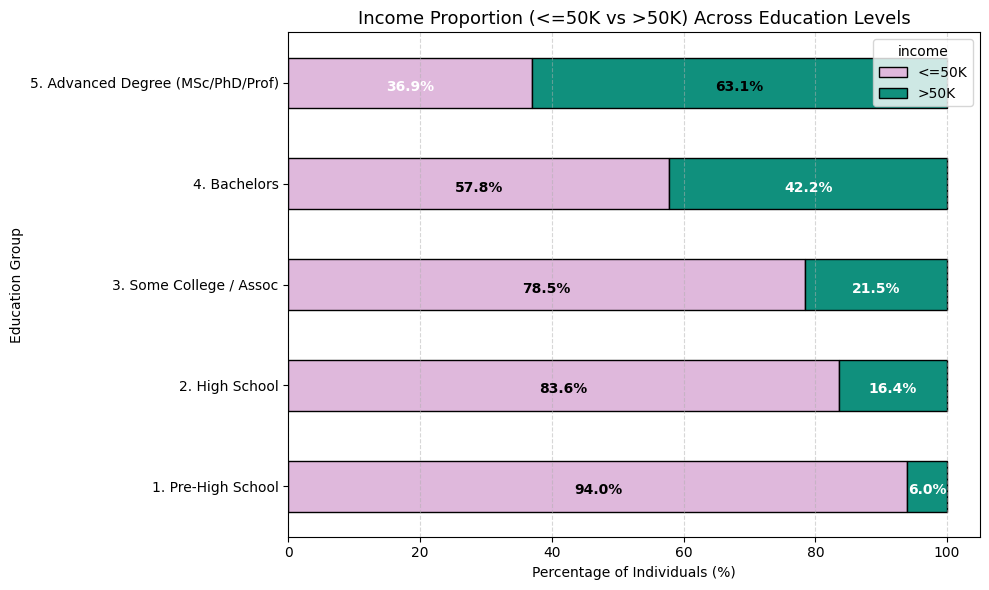

In [41]:
ax = prop_table.plot(kind='barh', stacked=True , color=['#dfb8dc', '#10907d'] , edgecolor='black' , figsize=(10,6))
plt.title('Income Proportion (<=50K vs >50K) Across Education Levels', fontsize=13)
plt.xlabel('Percentage of Individuals (%)')
plt.ylabel('Education Group')
plt.grid(axis = 'x' , alpha=0.5 , linestyle='--')

#show percentage
for n, x in enumerate([*prop_table.index.values]):
    for (proportion, count, y_loc) in zip(prop_table.loc[x], prop_table.loc[x], prop_table.loc[x].cumsum()):
        if proportion > 5:
            plt.text(x=y_loc - proportion/2, y=n - 0.08,s=f'{proportion:.1f}%',
                    color='black' if proportion>50 else 'white',fontweight='bold', ha='center')
plt.tight_layout()
plt.show()

## 7. Income Composition Across Education Groups

The normalized contingency table and stacked bar chart illustrate the distribution of the two income categories within each education group.

In the Pre-High School group, **93.98%** of individuals earn $50,000 or less, while only **6.02%** earn more than $50,000.

In contrast, the Advanced Degree group has a high-income rate of **63.08%**, while **36.92%** of its members earn $50,000 or less.

The visualization reinforces the descriptive findings: the composition of income categories differs substantially across education groups, with the proportion earning more than $50,000 increasing as educational attainment rises.

This pattern is consistent with the statistically significant Chi-Square result. Nevertheless, the chart represents an unadjusted comparison and does not account for other characteristics that may be associated with income.

## 8. Conclusion

This project examined the relationship between educational attainment and income category using exploratory data analysis, correlation measures, and statistical hypothesis testing.

The analysis was conducted on **30,139 observations** after removing records containing missing values and duplicate rows.

The descriptive results showed a consistent increase in the proportion of individuals earning more than $50,000 across the five education groups. The observed rate ranged from **6.02%** in the Pre-High School group to **63.08%** in the Advanced Degree group.

The point-biserial correlation was positive (**r = 0.3354, p < 0.001**), indicating a positive association between numerical education level and the binary high-income indicator. The Spearman correlation provides a complementary assessment of the monotonic relationship and should be interpreted using its corrected, rerun result.

The Chi-Square Test of Independence also identified a statistically significant association between education group and income category, **χ²(4) = 3928.41, p < 0.001**. Cramér's V was **0.3610**, indicating that the relationship was substantial in this sample.

Overall, the findings consistently indicate that higher educational attainment is associated with a greater likelihood of earning more than $50,000 annually in the analyzed dataset.

However, these results do not demonstrate that education directly causes higher income. Other factors, including age, occupation, work experience, and hours worked, may also contribute to income differences. In addition, removing incomplete observations may affect how representative the retained sample is of the original dataset.

Within these limitations, the project demonstrates how descriptive analysis, correlation measures, visualizations, and hypothesis testing can be combined to investigate relationships between categorical and ordered variables in a real-world dataset.